# Protocol

## Libraries

In [199]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.model_selection import cross_validate
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn import preprocessing
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import GridSearchCV

## Import and Tidy Data

In [176]:
df_train_y = pd.read_csv('data/Datasets_MLready/y_train.csv')
df_train_y.head()

,NO2,O3,PM10
0,17.20,44.33,18.81
1,9.33,49.89,16.57
2,12.80,46.59,27.35
3,24.10,41.80,19.33
4,8.67,50.66,11.73


In [177]:
df_train_X = pd.read_csv('data/Datasets_MLready/X_train_transformed.csv')
df_train_X.head()

,Month_sin__Month,Month_cos__Month,Day_sin__Day,Day_cos__Day,Weekday_sin__Weekday,Weekday_cos__Weekday,Time_sin__Time,Time_cos__Time,Spline_month__Month_sp_0,Spline_month__Month_sp_1,...,encoded__Location_Zch_Rosengartenstrasse,encoded__Location_Zch_Schimmelstrasse,encoded__Location_Zch_Stampfenbachstrasse,scaled__Hr,scaled__RainDur,scaled__T,scaled__WVv,scaled__StrGlo,scaled__meanVehicles,remainder__Year
0,-2.449294e-16,1.000000,0.433884,-0.900969,-0.781831,0.62349,-0.258819,0.965926,0.166667,0.666667,...,1.0,0.0,0.0,-0.106724,-0.347905,-0.442934,1.127894,-0.617743,-0.145789,2018.0
1,-2.449294e-16,1.000000,0.433884,-0.900969,-0.781831,0.62349,-0.258819,0.965926,0.166667,0.666667,...,0.0,1.0,0.0,-0.286880,-0.347905,-0.369828,-0.105097,-0.617743,-0.563898,2018.0
2,-2.449294e-16,1.000000,0.433884,-0.900969,-0.781831,0.62349,-0.258819,0.965926,0.166667,0.666667,...,0.0,0.0,1.0,-0.162810,-0.347905,-0.437893,4.097794,-0.617743,-0.864052,2018.0
3,5.000000e-01,0.866025,0.781831,0.623490,0.000000,1.00000,0.000000,1.000000,0.033083,0.529225,...,1.0,0.0,0.0,0.016779,-0.328655,-0.410163,0.849131,-0.617786,0.887373,2018.0
4,5.000000e-01,0.866025,0.781831,0.623490,0.000000,1.00000,0.000000,1.000000,0.033083,0.529225,...,0.0,1.0,0.0,-0.110690,-0.347905,-0.378651,0.205832,-0.617786,0.029038,2018.0


In [178]:
# Select columns to create two separate datasets with different time-encodings (Trigonometric and Spline)
spline_cols = list(df_train_X.filter(like="Spline_").columns)
scaled_cols = list(df_train_X.filter(like="scaled_").columns)
encoded_cols = list(df_train_X.filter(like="encoded_").columns)
year_col = list(df_train_X.filter(like="remainder_").columns)
tri_cols = list(df_train_X.iloc[:,0:8].columns)

In [179]:
# plotting a pairplot
# df_pairplot = df.drop(columns=["Datetime", "Month", "Weekday", "YearMonth"])
#
# sns.set_theme(style="ticks")
#
# sns.pairplot(df_pairplot, hue="Location")

In [180]:
# df[["Month", "Weekday", "Year"]] = df[["Month", "Weekday", "Year"]].astype("category")
#
# df.dtypes

## 3. Time-based cross-validation

In [181]:
# fixed training set size
tss = TimeSeriesSplit(n_splits=5,gap=24*2,max_train_size=24 * 365,test_size=24*30)

## 4. Model Evaluation

In [182]:
# model evaluation
def evaluate(model, X, y):
    ret = cross_validate(model, X, y, cv=tss, scoring=["neg_root_mean_squared_error"])
    rmse = -ret["test_neg_root_mean_squared_error"]
    print("%.2f ± %.2f" % (rmse.mean(), rmse.std()))

In [183]:
X_tri = df_train_X[encoded_cols + tri_cols + scaled_cols + year_col]
X_spl = df_train_X[encoded_cols + spline_cols + scaled_cols + year_col]

In [184]:
y_NO2 = df_train_y["NO2"]
y_O3 = df_train_y["O3"]
y_PM10 = df_train_y["PM10"]

In [185]:
df_train_y.describe()

,NO2,O3,PM10
count,171398.000000,171398.000000,171398.000000
mean,29.585936,45.986320,14.877335
std,17.374629,30.222047,9.619687
min,0.710000,-0.220000,-9.850000
25%,16.140000,21.350000,8.520000
50%,26.650000,44.960000,12.920000
75%,40.050000,66.140000,18.820000
max,308.120000,184.630000,593.440000


### Model 1 (e.g. Multiple Linear Regression)

In [186]:
# building linear regression model
model_lr = LinearRegression()

In [187]:
print("linear regression, trigonometric encoding, NO2")
evaluate(model_lr, X_tri, y_NO2)

print("linear regression, spline encoding, NO2")
evaluate(model_lr, X_spl, y_NO2)

print("linear regression, trigonometric encoding, O3")
evaluate(model_lr, X_tri, y_O3)

print("linear regression, spline encoding, O3")
evaluate(model_lr, X_spl, y_O3)

print("linear regression, trigonometric encoding, PM10")
evaluate(model_lr, X_tri, y_PM10)

print("linear regression, spline encoding, PM10")
evaluate(model_lr, X_spl, y_PM10)

linear regression, trigonometric encoding, NO2
11.16 ± 3.46
linear regression, spline encoding, NO2
12.04 ± 3.90
linear regression, trigonometric encoding, O3
19.19 ± 3.26
linear regression, spline encoding, O3
35.44 ± 34.50
linear regression, trigonometric encoding, PM10
6.73 ± 1.43
linear regression, spline encoding, PM10
11.68 ± 10.90


### Model 2 - Lasso

In [188]:
# Build and evaluate a basic model
alpha = 0.1
model_lasso = Lasso(alpha=alpha)

print("linear regression, trigonometric encoding, NO2")
evaluate(model_lasso, X_tri, y_NO2)

print("linear regression, spline encoding, NO2")
evaluate(model_lasso, X_spl, y_NO2)

print("linear regression, trigonometric encoding, O3")
evaluate(model_lasso, X_tri, y_O3)

print("linear regression, spline encoding, O3")
evaluate(model_lasso, X_spl, y_O3)

print("linear regression, trigonometric encoding, PM10")
evaluate(model_lasso, X_tri, y_PM10)

print("linear regression, spline encoding, PM10")
evaluate(model_lasso, X_spl, y_PM10)

linear regression, trigonometric encoding, NO2
11.09 ± 3.55
linear regression, spline encoding, NO2
11.23 ± 3.41
linear regression, trigonometric encoding, O3
18.69 ± 3.38
linear regression, spline encoding, O3
18.29 ± 3.26
linear regression, trigonometric encoding, PM10
6.51 ± 0.73
linear regression, spline encoding, PM10
6.23 ± 0.33


## 5. Feature selection

### Helper functions

In [209]:
# Helper function to compute normalized importance for Linear models
# TODO: For tree-based models make similar with .feature_importances_
def get_importance(model, feature_names):
    coef = np.abs(model.coef_)
    importance = coef / coef.sum() # normalized
    return pd.Series(importance, index=feature_names).sort_values(ascending=False)

# Build a grouping function
def group_features(feature_names):
    groups = {}
    for f in feature_names:
        # original variable name = prefix before first underscore
        base = f.split("__")[1].split("_")[0]
        groups.setdefault(base, []).append(f)
    return groups

# Compute grouped importance
def grouped_importance(model, X):
    coef = np.abs(model.coef_)
    norm = coef / coef.sum()
    imp = pd.Series(norm, index=X.columns)

    groups = group_features(X.columns)

    grouped = {
        base: imp[cols].sum()
        for base, cols in groups.items()
    }

    return pd.Series(grouped).sort_values(ascending=False)

# Make grouped plots
def plot_grouped_importance(tri_imp, spl_imp, model_name, feature_name):
    """
    Plot grouped feature importance for trig vs spline models.
    tri_imp and spl_imp are the grouped importance Series.
    """
    df = pd.DataFrame({
        "Trig importance": tri_imp,
        "Spline importance": spl_imp
    }).fillna(0)

    # Reorder the features for visualisation
    feature_order = ["Year", "Month", "Weekday", "Time", "Day",
                     "Location",
                     "Hr", "RainDur", "T", "WVv", "StrGlo",
                     "meanVehicles"]

    df = df.reindex(feature_order)
    # Drop variables that are not present in this model (just in case of some pre-selection)
    df = df.dropna(how="all")

    plt.figure(figsize=(10, 6))
    ax = df.plot(kind="bar", width=0.8)
    # Add numeric labels on top of each bar
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=3, rotation=45, fontsize=6)

    plt.title(f"{model_name} Feature Importance (Grouped) – {feature_name}")
    plt.ylabel("Normalized Importance")
    plt.xlabel("Original Variable")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

### Model 2 - Lasso

#### Feature importance analysis

In [190]:
# Train the models for the individual datasets
alpha = 0.1

lasso_tri_NO2 = Lasso(alpha=alpha).fit(X_tri, y_NO2)
lasso_spl_NO2 = Lasso(alpha=alpha).fit(X_spl, y_NO2)

lasso_tri_O3 = Lasso(alpha=alpha).fit(X_tri, y_O3)
lasso_spl_O3 = Lasso(alpha=alpha).fit(X_spl, y_O3)

lasso_tri_PM10 = Lasso(alpha=alpha).fit(X_tri, y_PM10)
lasso_spl_PM10 = Lasso(alpha=alpha).fit(X_spl, y_PM10)

# Compute importance for all 6 models
imp_lasso_tri_NO2 = get_importance(lasso_tri_NO2, X_tri.columns)
imp_lasso_spl_NO2 = get_importance(lasso_spl_NO2, X_spl.columns)

imp_lasso_tri_O3 = get_importance(lasso_tri_O3, X_tri.columns)
imp_lasso_spl_O3 = get_importance(lasso_spl_O3, X_spl.columns)

imp_lasso_tri_PM10 = get_importance(lasso_tri_PM10, X_tri.columns)
imp_lasso_spl_PM10 = get_importance(lasso_spl_PM10, X_spl.columns)

# Build grouped importance tables for all 6 models
g_imp_lasso_tri_NO2 = grouped_importance(lasso_tri_NO2, X_tri)
g_imp_lasso_spl_NO2 = grouped_importance(lasso_spl_NO2, X_spl)

g_imp_lasso_tri_O3 = grouped_importance(lasso_tri_O3, X_tri)
g_imp_lasso_spl_O3 = grouped_importance(lasso_spl_O3, X_spl)

g_imp_lasso_tri_PM10 = grouped_importance(lasso_tri_PM10, X_tri)
g_imp_lasso_spl_PM10 = grouped_importance(lasso_spl_PM10, X_spl)

<Figure size 1000x600 with 0 Axes>

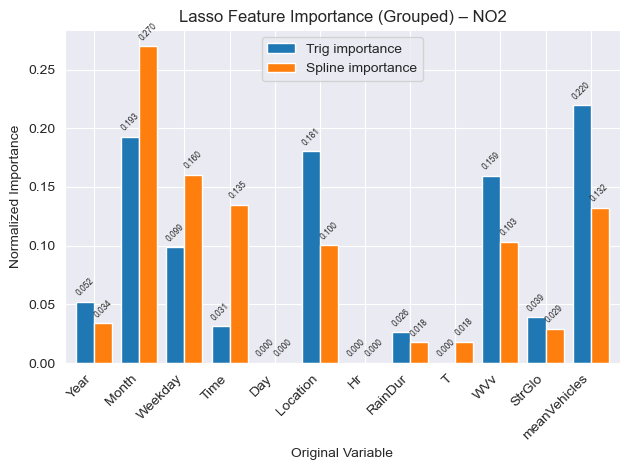

<Figure size 1000x600 with 0 Axes>

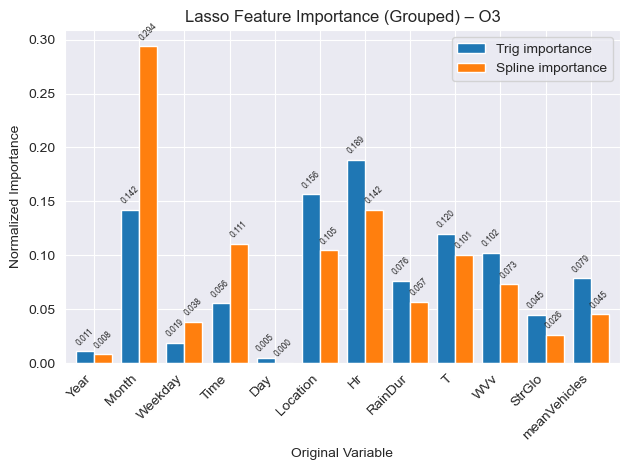

<Figure size 1000x600 with 0 Axes>

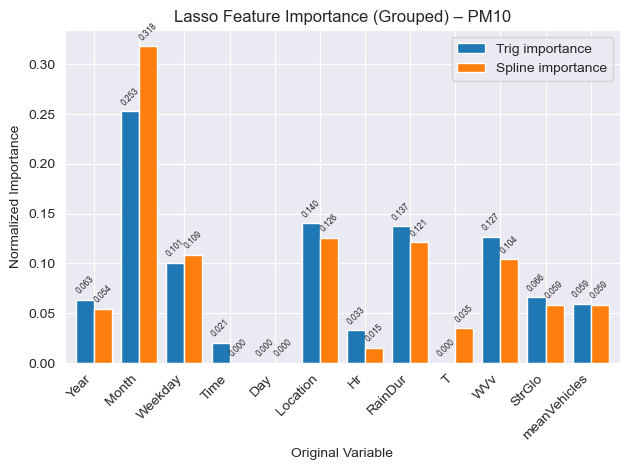

In [210]:
# Plot the grouped importance
plot_grouped_importance(g_imp_lasso_tri_NO2, g_imp_lasso_spl_NO2, "Lasso", "NO2")
plot_grouped_importance(g_imp_lasso_tri_O3,  g_imp_lasso_spl_O3, "Lasso", "O3")
plot_grouped_importance(g_imp_lasso_tri_PM10, g_imp_lasso_spl_PM10, "Lasso", "PM10")

#### Feature selection

No feature is standing out as clearly not important for all 3 pollutants. For this reason, we keep all features in the dataset for the Lasso model

## 6. Hyperparameter Tuning

### Model 1

### Model 2 - Lasso

In [197]:
# Find all hyperparams of your model with get_params()
model_lasso = Lasso()
model_lasso.get_params()

{'alpha': 1.0,
 'copy_X': True,
 'fit_intercept': True,
 'max_iter': 1000,
 'positive': False,
 'precompute': False,
 'random_state': None,
 'selection': 'cyclic',
 'tol': 0.0001,
 'warm_start': False}

Since Lasso model contains only few hyperparameters to tune, we will use Grid search

In [204]:
# Use a full grid over hyperparameters with a helper function
def tune_lasso(X, y, tss):
    """
    Run hyperparameter tuning for a single Lasso model using TimeSeriesSplit.
    """
    model = Lasso()

    param_grid = {
        "alpha": [0.001, 0.01, 0.1, 0.5, 1, 5, 10],
        "fit_intercept": [True, False],
        "max_iter": [5000]
    }

    search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=tss,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    search.fit(X, y)
    return search

# Compare tuning between the 6 models
tuned_lasso_tri_NO2 = tune_lasso(X_tri, y_NO2, tss)
tuned_lasso_spl_NO2 = tune_lasso(X_spl, y_NO2, tss)

tuned_lasso_tri_O3 = tune_lasso(X_tri, y_O3, tss)
tuned_lasso_spl_O3 = tune_lasso(X_spl, y_O3, tss)

tuned_lasso_tri_PM10 = tune_lasso(X_tri, y_PM10, tss)
tuned_lasso_spl_PM10 = tune_lasso(X_spl, y_PM10, tss)

# Put them in a list for easy print
tuned_lasso_models = [
    ("NO2 – Trig",   tuned_lasso_tri_NO2),
    ("NO2 – Spline", tuned_lasso_spl_NO2),
    ("O3 – Trig",    tuned_lasso_tri_O3),
    ("O3 – Spline",  tuned_lasso_spl_O3),
    ("PM10 – Trig",  tuned_lasso_tri_PM10),
    ("PM10 – Spline",tuned_lasso_spl_PM10)
]

# Summarize result
for name, model in tuned_lasso_models:
    print(f"Model: {name}")
    print(f"Best Score: {model.best_score_}")
    print(f"Best Hyperparameters: {model.best_params_}")
    print()

Model: NO2 – Trig
Best Score: -11.089663003547487
Best Hyperparameters: {'alpha': 0.1, 'fit_intercept': True, 'max_iter': 5000}

Model: NO2 – Spline
Best Score: -10.904957652670957
Best Hyperparameters: {'alpha': 0.01, 'fit_intercept': True, 'max_iter': 5000}

Model: O3 – Trig
Best Score: -17.453407661931582
Best Hyperparameters: {'alpha': 1, 'fit_intercept': True, 'max_iter': 5000}

Model: O3 – Spline
Best Score: -17.273447150222957
Best Hyperparameters: {'alpha': 0.5, 'fit_intercept': True, 'max_iter': 5000}

Model: PM10 – Trig
Best Score: -6.2093176156536245
Best Hyperparameters: {'alpha': 0.5, 'fit_intercept': True, 'max_iter': 5000}

Model: PM10 – Spline
Best Score: -6.180739875628598
Best Hyperparameters: {'alpha': 0.5, 'fit_intercept': True, 'max_iter': 5000}



### Model 3

## 7. Model Evaluation Metrics

averaged across CV splits during model selection
reported on the final test year (2025)
- RMSE
- MAE

## 8. Model Selection

Compare all models (e.g. linear regression, random forest, ...)

- Mean CV RMSE
- Stability across folds (standard deviation)
- Interpretability
- Computational complexity

## 9. Final Training and Testing

With the best model only, not all of them

- The selected model is refit on all training data (2018–2024)
- Predictions are generated for 2025
- Final performance is reported on the test set

### Model 1 (Multiple Linear Regression)

In [192]:
# fitting the model
model_lr.fit(X_tri, y_NO2)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [193]:
df_test_X = pd.read_csv("data/Datasets_MLready/X_test_transformed.csv")
df_test_y = pd.read_csv("data/Datasets_MLready/y_test.csv")

In [194]:
y_NO2_test = df_test_y["NO2"]
y_NO2_test.describe()

count    25853.000000
mean        23.773432
std         13.584978
min          0.690000
25%         13.380000
50%         21.790000
75%         31.970000
max         95.510000
Name: NO2, dtype: float64

In [195]:
X_tri_test = df_test_X[encoded_cols + tri_cols + scaled_cols]
X_spl_test = df_test_X[spline_cols + tri_cols + scaled_cols]

In [196]:
predictions = model_lr.predict(X_tri_test)

ValueError: The feature names should match those that were passed during fit.
Feature names seen at fit time, yet now missing:
- remainder__Year


In [19]:
# model evaluation
print('mean_squared_error:', mean_squared_error(y_NO2_test, predictions))
print('mean_absolute_error:', mean_absolute_error(y_NO2_test, predictions))

mean_squared_error: 144.96042374933515
mean_absolute_error: 9.889888824026027
